In [ ]:
# Wine Quality Prediction Using Machine Learning

## Objective
To predict wine quality using physicochemical properties and compare three classification models: Random Forest, Stochastic Gradient Descent (SGD), and Support Vector Classifier (SVC).

## Dataset
UCI Wine Quality Dataset — Red Wine.

## Workflow
1. Dataset loading and inspection
2. Exploratory Data Analysis (EDA)
3. Class distribution and imbalance analysis
4. Quality-score grouping
5. Stratified train/test split
6. Model training and evaluation
7. Feature importance and model comparison

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
file_path = Path("data/winequality-red.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "File not found. Make sure winequality-red.csv "
        "is inside the data folder of your project."
    )

df = pd.read_csv(file_path, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset loaded successfully!
Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

First five rows:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## 1. Data Quality Analysis

In this step, we check the dataset's dimensions, column names, missing values, duplicate records, and data types. These checks help us understand whether the data needs cleaning before modelling.

In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe().T.round(2))

Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:


,Data Type
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64



Missing values in each column:


,Missing Values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0



Total missing values: 0
Duplicate rows: 240

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.32,1.74,4.60,7.10,7.90,9.20,15.90
volatile acidity,1599.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1599.0,0.27,0.19,0.00,0.09,0.26,0.42,1.00
residual sugar,1599.0,2.54,1.41,0.90,1.90,2.20,2.60,15.50
chlorides,1599.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1599.0,15.87,10.46,1.00,7.00,14.00,21.00,72.00
total sulfur dioxide,1599.0,46.47,32.90,6.00,22.00,38.00,62.00,289.00
density,1599.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1599.0,3.31,0.15,2.74,3.21,3.31,3.40,4.01
sulphates,1599.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


### Analysis

- The dataset contains physicochemical measurements of red wine and a `quality` target column.
- Missing values need to be checked before training the models.
- Duplicate rows may represent repeated records. We will inspect them but will not automatically remove them without considering the dataset.
- Summary statistics help identify the range, average, and variation of each feature.

## 2. Wine Quality Class Distribution

The target variable is `quality`, which contains numerical ratings assigned to wines. We first examine how frequently each quality score occurs.

Class imbalance is important because a model trained on an imbalanced dataset may predict common quality scores more successfully than rare scores.

,Count,Percentage
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


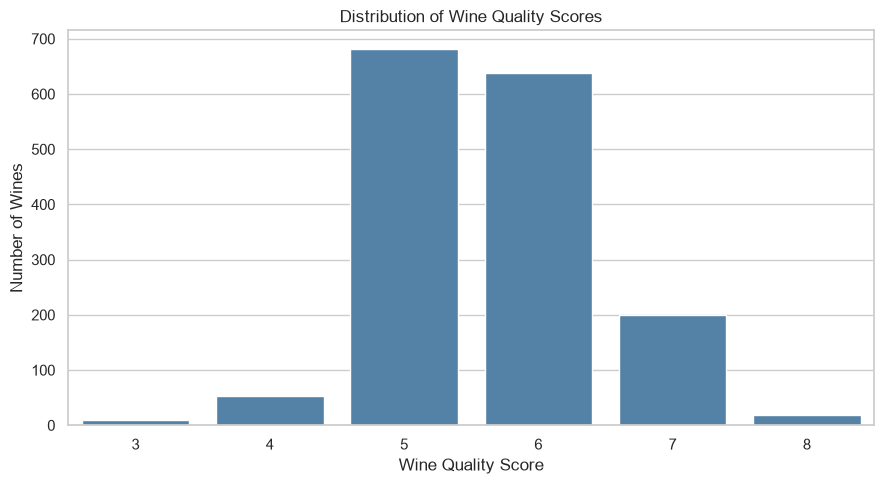

In [5]:
quality_counts = df["quality"].value_counts().sort_index()
quality_percentages = (
    df["quality"].value_counts(normalize=True).sort_index() * 100
)

quality_distribution = pd.DataFrame({
    "Count": quality_counts,
    "Percentage": quality_percentages.round(2)
})

display(quality_distribution)

plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="quality", color="steelblue")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality Score")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

### Analysis

Examine the bar chart and the distribution table.

- The tallest bars represent the most common quality scores.
- Shorter bars indicate underrepresented quality scores.
- If some scores have very few samples, a classifier may struggle to learn their patterns reliably.

Use the actual counts from the output when discussing which quality scores are most and least common.

## 3. Exploratory Data Analysis

EDA helps us understand the distributions of the chemical features, identify unusual values, and explore relationships between the physicochemical properties and wine quality.

We will visualize all chemical features and create a correlation heatmap.

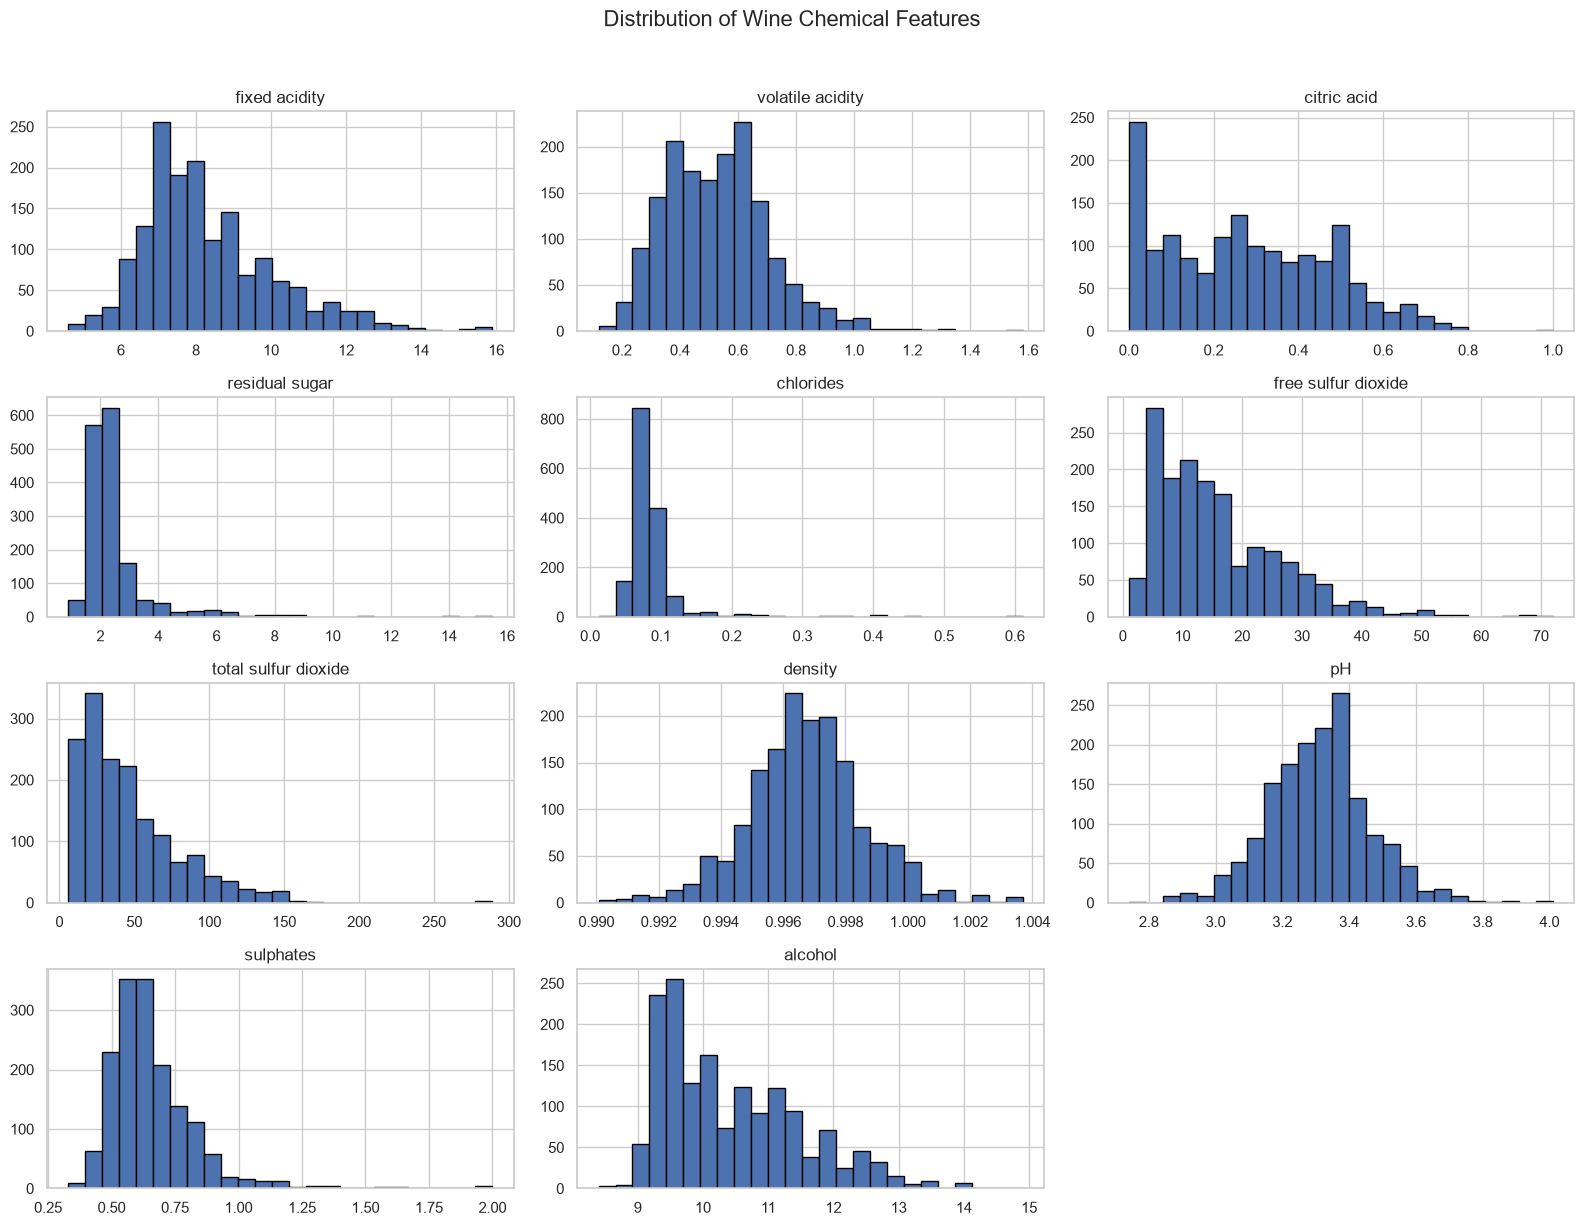

In [6]:
chemical_features = df.drop(columns="quality").columns

df[chemical_features].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Chemical Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### Analysis of Feature Distributions

Review the histograms for all chemical features.

- A roughly symmetric histogram suggests values are distributed around a central region.
- A skewed histogram indicates that values are concentrated more toward one end.
- Unusual extreme values should be investigated rather than automatically deleted.

Different chemical features have different measurement scales and distributions, which is important when selecting and preparing models.

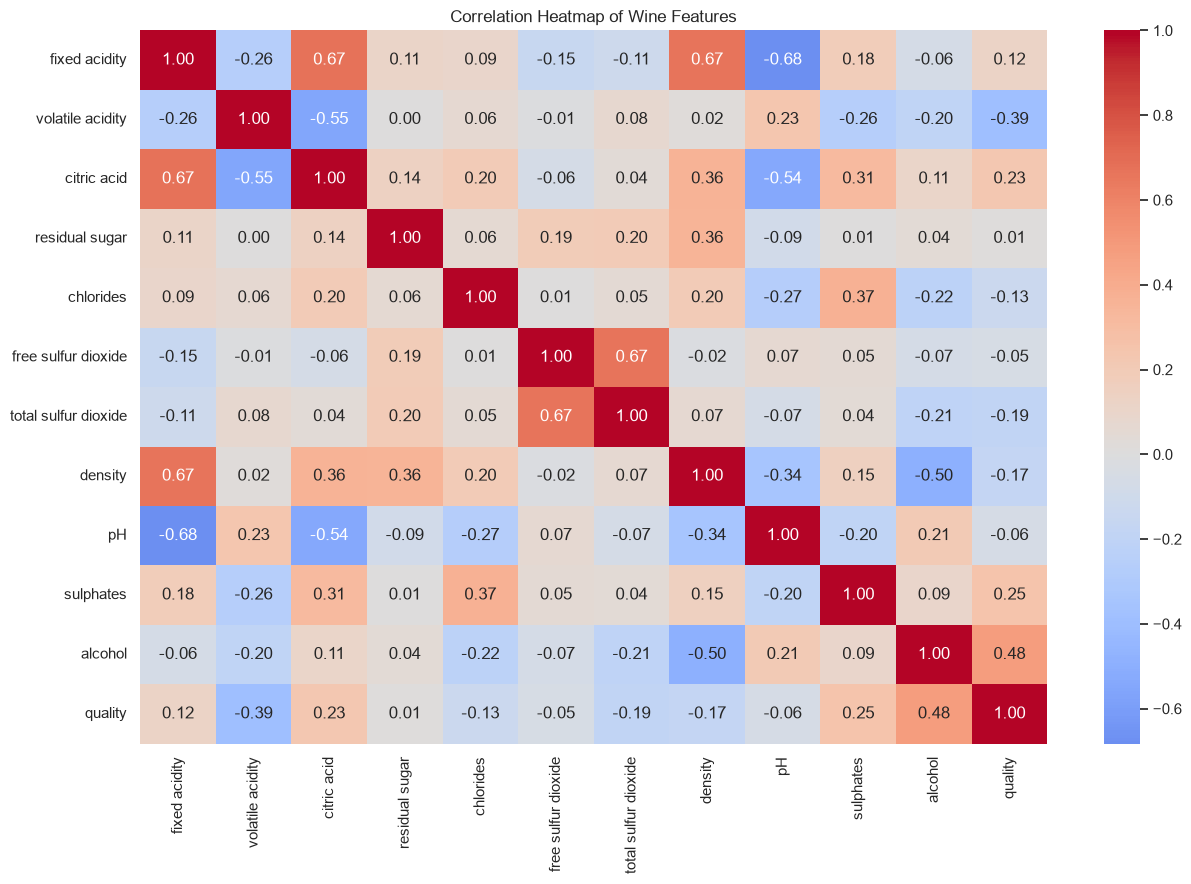

Features most positively correlated with quality:


,Correlation with Quality
alcohol,0.476166
sulphates,0.251397
citric acid,0.226373
fixed acidity,0.124052
residual sugar,0.013732
free sulfur dioxide,-0.050656
pH,-0.057731
chlorides,-0.128907
density,-0.174919
total sulfur dioxide,-0.185100


Features most negatively correlated with quality:


,Correlation with Quality
volatile acidity,-0.390558
total sulfur dioxide,-0.185100
density,-0.174919
chlorides,-0.128907
pH,-0.057731
free sulfur dioxide,-0.050656
residual sugar,0.013732
fixed acidity,0.124052
citric acid,0.226373
sulphates,0.251397


In [8]:
plt.figure(figsize=(13, 9))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Wine Features")
plt.tight_layout()
plt.show()

print("Features most positively correlated with quality:")
display(
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values(ascending=False)
    .to_frame("Correlation with Quality")
)

print("Features most negatively correlated with quality:")
display(
    correlation_matrix["quality"]
    .drop("quality")
    .sort_values()
    .to_frame("Correlation with Quality")
)

### Correlation Analysis

- Correlation values close to `+1` indicate a strong positive linear relationship.
- Values close to `-1` indicate a strong negative linear relationship.
- Values near `0` indicate a weak linear relationship.

Use the heatmap and printed tables to identify the features most positively and negatively associated with quality. Correlation does not prove causation, and these relationships alone do not establish which features are most useful to a classifier.

## 4. Feature Engineering: Three Quality Classes

The original quality scores are grouped into three categories:

- Low quality: score less than or equal to 5
- Medium quality: score equal to 6
- High quality: score greater than or equal to 7

This grouping reduces the number of target classes and makes the predictions easier to interpret. However, the three classes may still be imbalanced, so we will inspect their distribution before splitting the data.

,Count,Percentage
quality_category,,
Low,744,46.53
Medium,638,39.90
High,217,13.57


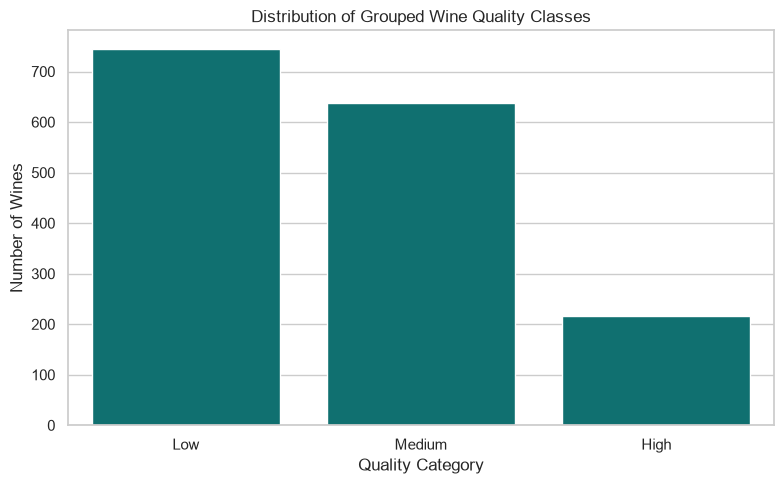

In [9]:
df["quality_category"] = pd.cut(
    df["quality"],
    bins=[-float("inf"), 5, 6, float("inf")],
    labels=["Low", "Medium", "High"]
)

class_counts = df["quality_category"].value_counts().reindex(
    ["Low", "Medium", "High"]
)

class_percentages = (
    df["quality_category"].value_counts(normalize=True).reindex(
        ["Low", "Medium", "High"]
    ) * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_distribution)

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="quality_category",
    order=["Low", "Medium", "High"],
    color="teal"
)
plt.title("Distribution of Grouped Wine Quality Classes")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

### Analysis of Class Imbalance

Compare the number of Low, Medium, and High samples.

If one category has substantially fewer observations, the dataset is imbalanced. A model can achieve a reasonable accuracy by predicting the majority class frequently while performing poorly on minority classes.

We will use stratified splitting to preserve class proportions in the training and testing sets. We will also compare precision, recall, and F1-score so that evaluation is not based on accuracy alone.

## 5. Train/Test Split with Stratification

We will use the 11 physicochemical measurements as input features and `quality_category` as the target.

The original `quality` column is excluded from the input features because it was used to create the target category. Including it would cause data leakage and make the model's performance misleading.

The dataset is split into 80% training data and 20% testing data. Stratification preserves the approximate class proportions in both sets.

In [10]:
X = df.drop(columns=["quality", "quality_category"]).copy()
y = df["quality_category"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining class proportions (%):")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

print("\nTesting class proportions (%):")
display((y_test.value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

print("\nStratified split completed successfully!")

Training features shape: (1279, 11)
Testing features shape: (320, 11)

Training class proportions (%):


,Percentage
quality_category,
Low,46.52
Medium,39.87
High,13.60



Testing class proportions (%):


,Percentage
quality_category,
Low,46.56
Medium,40.00
High,13.44



Stratified split completed successfully!


### Analysis

The training data is used to fit the models, while the testing data evaluates how well they perform on unseen examples.

Compare the class percentages in the training and testing sets. They should be similar because stratification was applied.

We exclude `quality` from the predictors to prevent target leakage.

## 6. Model Training

Three classifiers are trained using the same training and testing split.

- **Random Forest:** combines multiple decision trees to learn nonlinear relationships.
- **SGD Classifier:** learns a classification boundary using stochastic gradient-based optimization.
- **SVC:** finds decision boundaries that separate classes, using a nonlinear kernel by default.

For SGD and SVC, StandardScaler is included in a pipeline. The scaler is fitted only on training data, helping prevent information leakage from the test set.

In [11]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SGD Classifier": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            max_iter=3000,
            tol=1e-3,
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ]),

    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ])
}

trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)

    print(f"{name} training completed.\n")

print("All three models have been trained successfully!")

Training Random Forest...
Random Forest training completed.

Training SGD Classifier...
SGD Classifier training completed.

Training SVC...
SVC training completed.

All three models have been trained successfully!


### Analysis of Model Training

All three classifiers are trained using the same training data for a fair comparison.

The `class_weight="balanced"` setting adjusts class weights according to their frequencies during training. This can help models pay more attention to underrepresented classes, but it does not guarantee better performance. The test metrics will show whether each model handles the classes effectively.

## 7. Model Evaluation

Each model is evaluated using:

- **Accuracy:** proportion of correctly classified wines.
- **Precision:** how many predictions for a class were correct.
- **Recall:** how many actual examples of a class were identified.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** shows correct and incorrect predictions for each class.

We will inspect the classification report and confusion matrix for every model.

In [12]:
results = []

for name, y_pred in predictions.items():
    accuracy = accuracy_score(y_test, y_pred)

    print("=" * 65)
    print(name)
    print("=" * 65)
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    ))

    report = classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        output_dict=True,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1-Score": report["macro avg"]["f1-score"],
        "Weighted F1-Score": report["weighted avg"]["f1-score"]
    })

Random Forest
Accuracy: 0.7375 (73.75%)

Classification Report:
              precision    recall  f1-score   support

         Low       0.82      0.81      0.81       149
      Medium       0.71      0.66      0.68       128
        High       0.58      0.74      0.65        43

    accuracy                           0.74       320
   macro avg       0.70      0.74      0.72       320
weighted avg       0.74      0.74      0.74       320

SGD Classifier
Accuracy: 0.5531 (55.31%)

Classification Report:
              precision    recall  f1-score   support

         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128
        High       0.23      0.33      0.27        43

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320

SVC
Accuracy: 0.6094 (60.94%)

Classification Report:
              precision    recall  f1-score   support



### Analysis of Classification Reports

Compare the precision, recall, and F1-score for Low, Medium, and High wine quality.

Macro F1-score gives equal importance to each class, making it useful when class sizes differ. Weighted F1-score accounts for the number of observations in each class.

A strong model should perform reasonably well across all three categories rather than simply predicting the most common class.

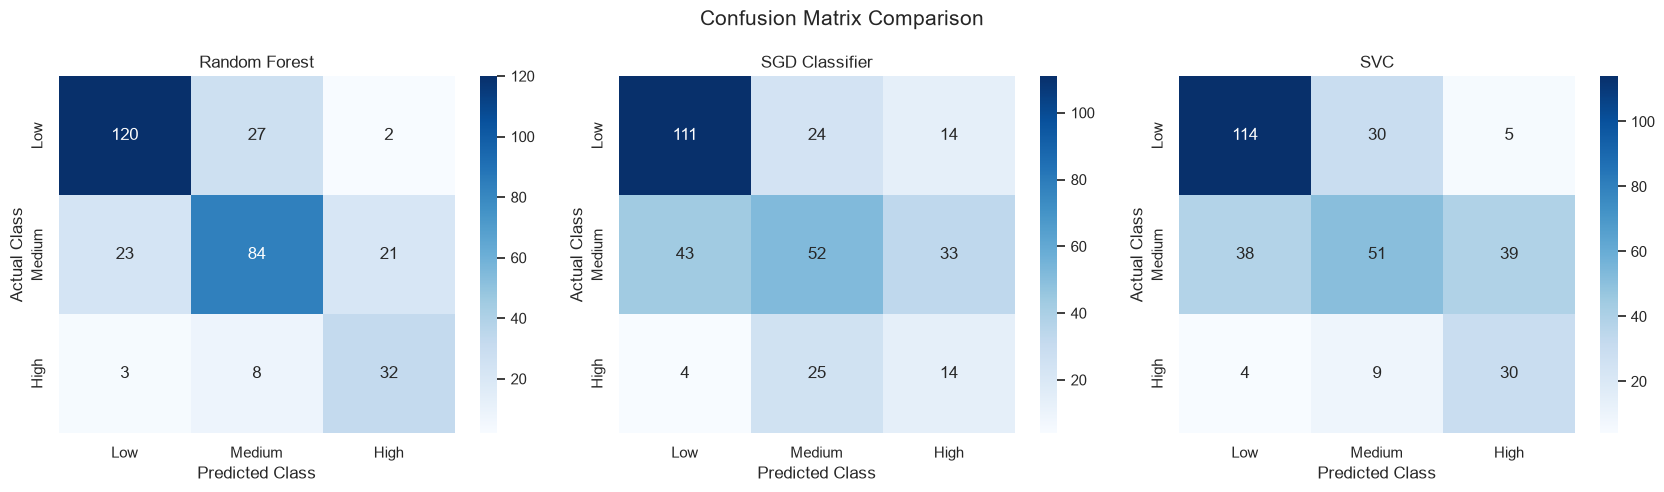

In [13]:
class_labels = ["Low", "Medium", "High"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle("Confusion Matrix Comparison", fontsize=15)
plt.tight_layout()
plt.show()

### Confusion Matrix Analysis

The diagonal cells represent correct predictions. The cells outside the diagonal represent misclassifications.

Check whether the models confuse Medium wines with Low or High wines. Also examine how many High-quality wines are correctly identified. These patterns help explain the strengths and weaknesses of each classifier.

## 8. Random Forest Feature Importance

Random Forest estimates feature importance based on how much each feature contributes to reducing impurity across its trees.

We will rank the chemical properties and plot the most important features. This helps identify which measurements were most useful to the trained Random Forest model.

,Feature,Importance
10,alcohol,0.167002
9,sulphates,0.115536
1,volatile acidity,0.112465
6,total sulfur dioxide,0.094816
2,citric acid,0.086781
7,density,0.083796
4,chlorides,0.074134
0,fixed acidity,0.071642
8,pH,0.066803
5,free sulfur dioxide,0.064319


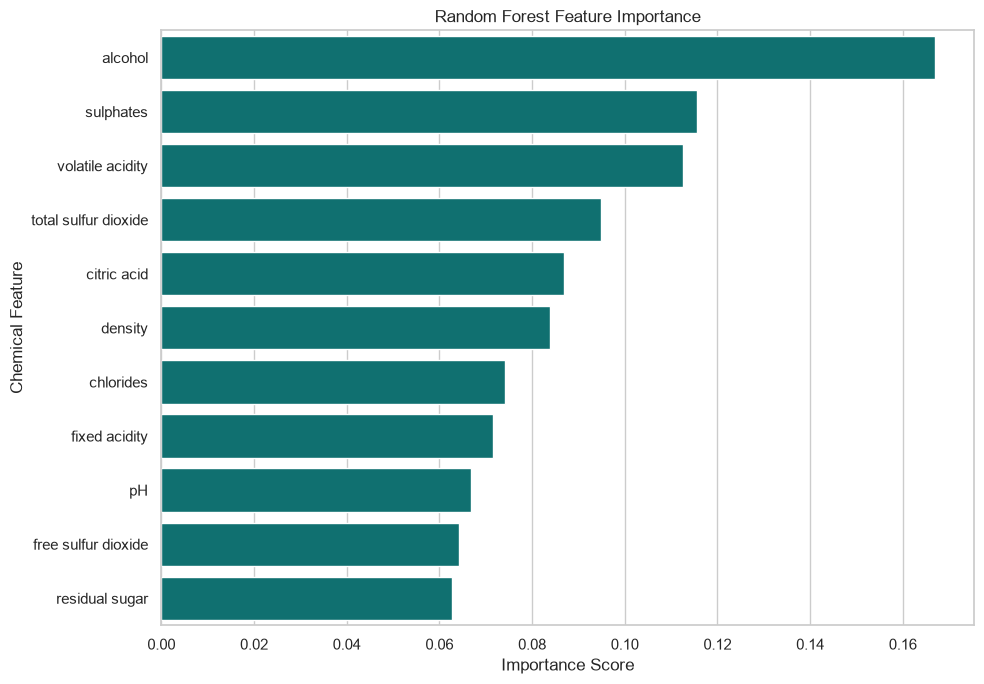

In [14]:
rf_model = trained_models["Random Forest"]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    color="teal"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

The features at the top of the chart contribute more to the Random Forest's impurity-based importance measure than those at the bottom.

Use the actual chart to identify the leading features. Importance does not prove that a feature causes higher wine quality, and impurity-based importance can be affected by feature characteristics and correlations.

## 9. Model Performance Comparison

We compare the three classifiers side by side using accuracy, macro precision, macro recall, macro F1-score, and weighted F1-score.

Macro F1-score is particularly useful for comparing performance across all quality categories when the dataset is imbalanced.

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Random Forest,0.7375,0.7032,0.7353,0.7156,0.7386
1,SVC,0.6094,0.5676,0.6204,0.5761,0.6041
2,SGD Classifier,0.5531,0.4823,0.4923,0.4822,0.5545


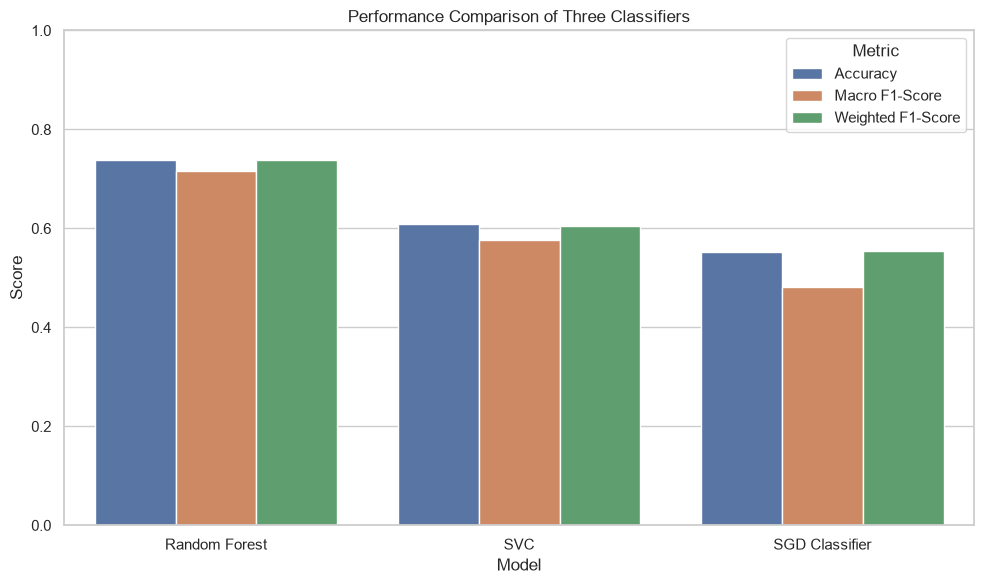

In [15]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Macro F1-Score",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

plt.figure(figsize=(10, 6))
comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1-Score", "Weighted F1-Score"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Three Classifiers")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.tight_layout()
plt.show()

### Model Comparison Analysis

Review the comparison table and chart.

- Higher accuracy indicates a greater proportion of correct predictions.
- Higher macro F1-score indicates a better balance of precision and recall across classes.
- Weighted F1-score reflects performance while accounting for class frequency.

The model with the highest macro F1-score is the initial candidate for handling class imbalance. Before selecting it for deployment, also inspect the individual class recall values and consider the intended use of the predictions.

## 10. Export Results

We save the model comparison, Random Forest feature importance, and predictions into CSV files. These files make it easier to review and share the project's results without rerunning every analysis.

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison_path = output_dir / "model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

# Save Random Forest feature importance
importance_path = output_dir / "random_forest_feature_importance.csv"
feature_importance.to_csv(importance_path, index=False)

# Save actual and predicted classes
prediction_results = pd.DataFrame({
    "Actual_Quality": y_test.reset_index(drop=True),
})

for name, y_pred in predictions.items():
    prediction_results[f"{name}_Prediction"] = pd.Series(y_pred).reset_index(drop=True)

predictions_path = output_dir / "wine_quality_predictions.csv"
prediction_results.to_csv(predictions_path, index=False)

print("All result files saved successfully:")
print(comparison_path.resolve())
print(importance_path.resolve())
print(predictions_path.resolve())

In [16]:
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison
comparison_path = output_dir / "model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

# Save Random Forest feature importance
importance_path = output_dir / "random_forest_feature_importance.csv"
feature_importance.to_csv(importance_path, index=False)

# Save actual and predicted classes
prediction_results = pd.DataFrame({
    "Actual_Quality": y_test.reset_index(drop=True),
})

for name, y_pred in predictions.items():
    prediction_results[f"{name}_Prediction"] = pd.Series(y_pred).reset_index(drop=True)

predictions_path = output_dir / "wine_quality_predictions.csv"
prediction_results.to_csv(predictions_path, index=False)

print("All result files saved successfully:")
print(comparison_path.resolve())
print(importance_path.resolve())
print(predictions_path.resolve())

All result files saved successfully:
C:\Users\hi\Documents\OIBSIP\Wine-Quality-Prediction\output\model_comparison.csv
C:\Users\hi\Documents\OIBSIP\Wine-Quality-Prediction\output\random_forest_feature_importance.csv
C:\Users\hi\Documents\OIBSIP\Wine-Quality-Prediction\output\wine_quality_predictions.csv


### Export Analysis

The output folder now contains:

1. `model_comparison.csv` — evaluation metrics for the three models.
2. `random_forest_feature_importance.csv` — feature importance scores.
3. `wine_quality_predictions.csv` — actual test categories and model predictions.

These files provide evidence of the model evaluation and make the results easier to inspect.

## 11. Conclusion

This project explored the UCI Red Wine Quality dataset and used physicochemical properties to classify wine into Low, Medium, and High quality categories.

The workflow included data inspection, exploratory data analysis, class imbalance analysis, feature engineering, stratified splitting, and training three classifiers: Random Forest, SGD Classifier, and SVC.

The models were evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. Random Forest feature importance was also examined to understand which chemical measurements were most useful for prediction.

The final model should be selected based on the measured test-set results, particularly macro F1-score and the recall of each class. No model should be declared the best until the actual evaluation results have been reviewed.

### Limitations

- The three quality categories simplify the original numerical ratings and depend on the selected thresholds.
- Class imbalance may still affect the predictions even after using class weights.
- Model performance on this dataset may not generalize to other wines or production conditions.
- Feature importance and correlations indicate patterns in the data but do not establish causation.

### References

- UCI Machine Learning Repository: [Wine Quality Dataset](https://archive.ics.uci.edu/dataset/186/wine+quality)
- Scikit-learn: [Random Forest Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- Scikit-learn: [SGD Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDClassifier.html)
- Scikit-learn: [Support Vector Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)